In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("data/Unemployment in India.csv")

print("Dataset loaded successfully!")
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'data/Unemployment in India.csv'

In [3]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles and folders:")
print(os.listdir())

Current folder:
c:\Users\jadha\OneDrive\Desktop\CodeAlpha_Unemployment_Analysis

Files and folders:
['.venv', 'data', 'Unemployment_Analysis.ipynb']


In [4]:
import os

print(os.listdir("data"))

['Unemployment in India (1).csv', 'Unemployment_Rate_upto_11_2020.csv']


In [5]:
df = pd.read_csv("data/Unemployment in India (1).csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
           Region         Date  Frequency   Estimated Unemployment Rate (%)  \
0  Andhra Pradesh   31-05-2019    Monthly                              3.65   
1  Andhra Pradesh   30-06-2019    Monthly                              3.05   
2  Andhra Pradesh   31-07-2019    Monthly                              3.75   
3  Andhra Pradesh   31-08-2019    Monthly                              3.32   
4  Andhra Pradesh   30-09-2019    Monthly                              5.17   

    Estimated Employed   Estimated Labour Participation Rate (%)   Area  
0           11999139.0                                     43.24  Rural  
1           11755881.0                                     42.05  Rural  
2           12086707.0                                     43.50  Rural  
3           12285693.0                                     43.97  Rural  
4           12256762.0                                     44.68  Rural  


In [6]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (768, 7)

Column Names:
Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), st

In [7]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64


In [8]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Display rows containing missing values
missing_rows = df[df.isnull().any(axis=1)]

print("Number of rows with missing values:", len(missing_rows))
display(missing_rows)

Number of rows with missing values: 28


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Remove rows containing only missing values
df = df.dropna(how="all")

# Check the updated dataset
print("Updated Dataset Shape:", df.shape)

# Check missing values again
print("\nMissing Values:")
print(df.isnull().sum())

Updated Dataset Shape: (740, 7)

Missing Values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


In [10]:
# Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [11]:
# Convert Date column to datetime format
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

# Check the data type
print(df["Date"].dtype)

# Display the first 5 dates
print(df["Date"].head())

datetime64[us]
0   2019-05-31
1   2019-06-30
2   2019-07-31
3   2019-08-31
4   2019-09-30
Name: Date, dtype: datetime64[us]


In [12]:
# Generate descriptive statistics
df.describe()

,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


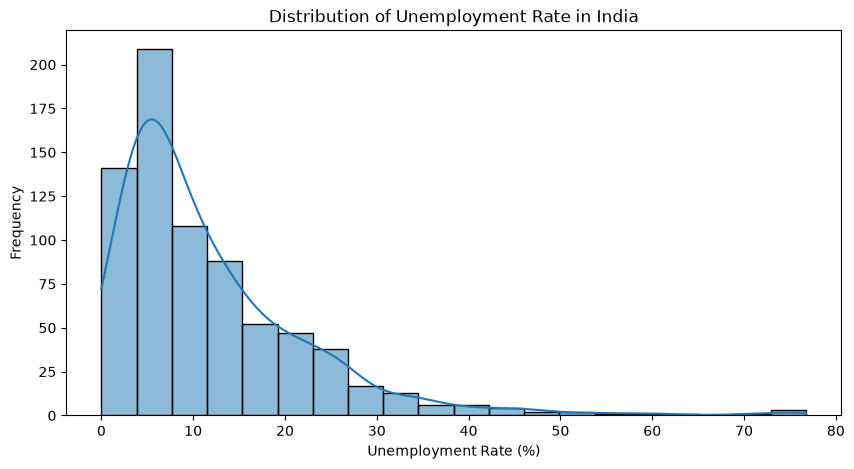

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(df["Estimated Unemployment Rate (%)"], bins=20, kde=True)

plt.title("Distribution of Unemployment Rate in India")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Frequency")

plt.show()

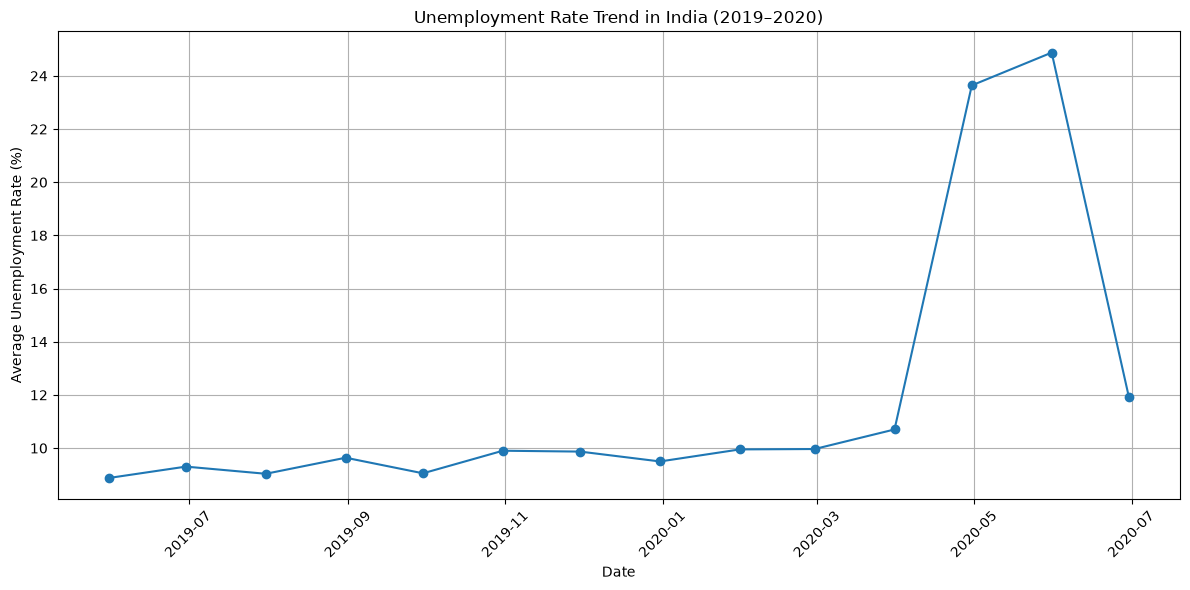

In [14]:
# Calculate average unemployment rate for each date
unemployment_trend = df.groupby("Date")[
    "Estimated Unemployment Rate (%)"
].mean()

# Plot the unemployment trend
plt.figure(figsize=(12, 6))

plt.plot(unemployment_trend.index,
         unemployment_trend.values,
         marker="o")

plt.title("Unemployment Rate Trend in India (2019–2020)")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
# Calculate average unemployment rate by region
region_unemployment = df.groupby("Region")[
    "Estimated Unemployment Rate (%)"
].mean().sort_values(ascending=False)

# Display the results
print("Average Unemployment Rate by Region:")
print(region_unemployment)

Average Unemployment Rate by Region:
Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64


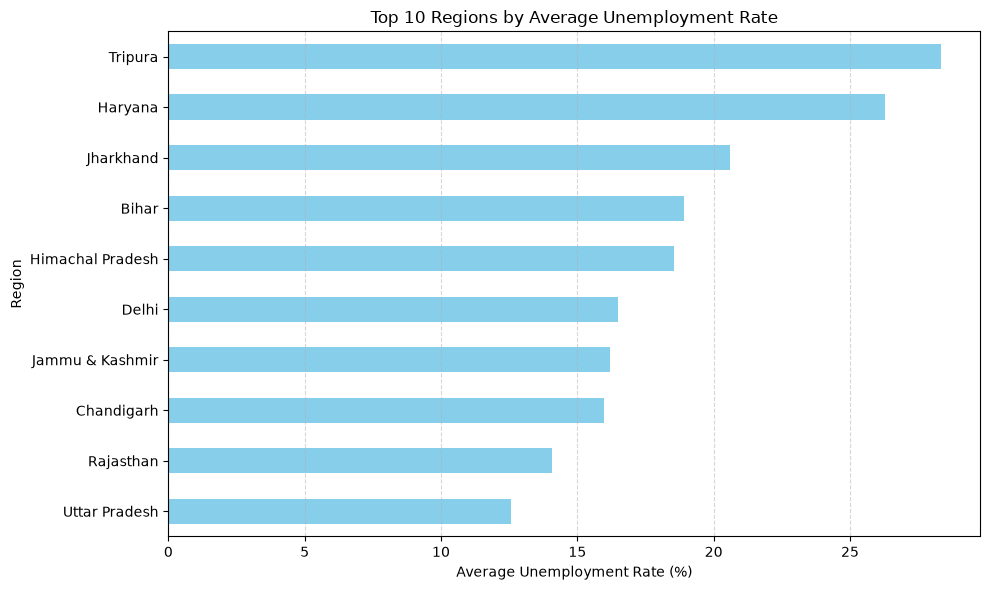

In [16]:
# Select the 10 regions with the highest average unemployment rates
top_10_regions = region_unemployment.head(10).sort_values()

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

top_10_regions.plot(kind="barh", color="skyblue")

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [17]:
# Calculate average unemployment rate by area
area_unemployment = df.groupby("Area")[
    "Estimated Unemployment Rate (%)"
].mean()

print("Average Unemployment Rate by Area:")
print(area_unemployment)

Average Unemployment Rate by Area:
Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64


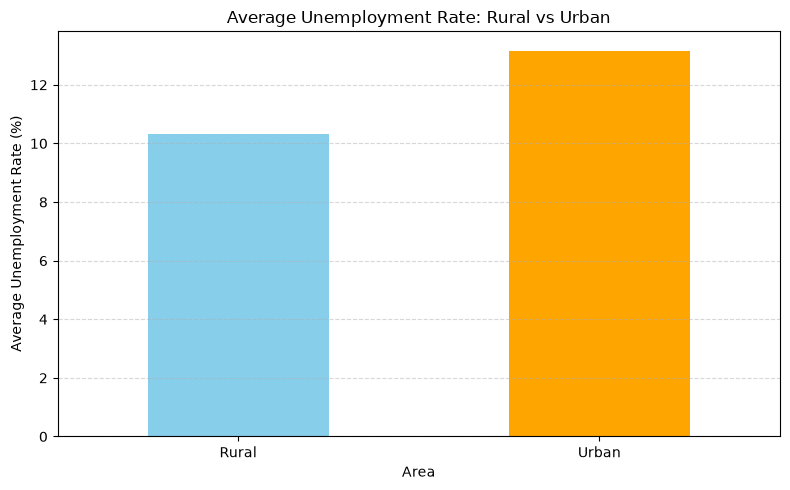

In [18]:
# Create a bar chart
plt.figure(figsize=(8, 5))

area_unemployment.plot(kind="bar", color=["skyblue", "orange"])

plt.title("Average Unemployment Rate: Rural vs Urban")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [19]:
# Separate the data into two periods
df["Period"] = df["Date"].apply(
    lambda date: "Before April 2020" if date < pd.Timestamp("2020-04-01")
    else "April-June 2020"
)

# Calculate average unemployment rate for each period
covid_analysis = df.groupby("Period")[
    "Estimated Unemployment Rate (%)"
].mean()

print("Average Unemployment Rate by Period:")
print(covid_analysis)

Average Unemployment Rate by Period:
Period
April-June 2020      20.194342
Before April 2020     9.614864
Name: Estimated Unemployment Rate (%), dtype: float64


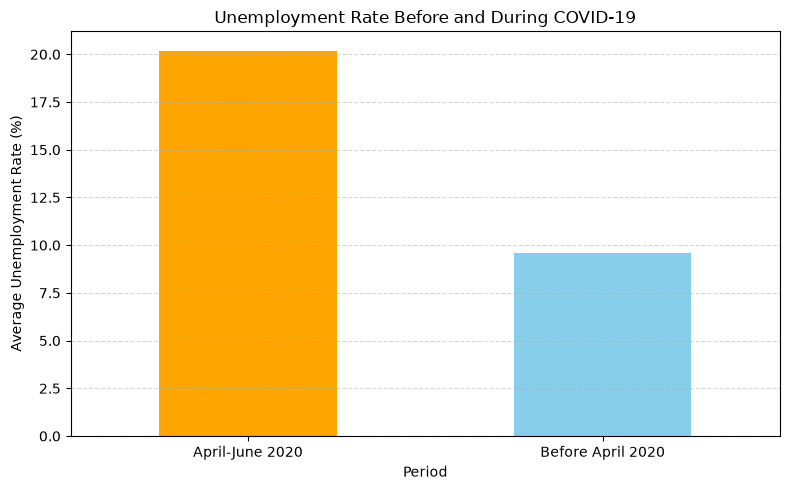

In [20]:
# Plot unemployment rates for the two periods
plt.figure(figsize=(8, 5))

covid_analysis.plot(kind="bar", color=["orange", "skyblue"])

plt.title("Unemployment Rate Before and During COVID-19")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [21]:
# Final dataset verification
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Final Dataset Shape: (740, 8)

Missing Values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
Period                                     0
dtype: int64

Column Names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area', 'Period']

First 5 Rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,Period
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,Before April 2020
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,Before April 2020
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,Before April 2020
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,Before April 2020
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,Before April 2020


## Conclusion

The Unemployment Analysis with Python project helped explore unemployment trends in India using data from May 2019 to June 2020. The dataset was cleaned by removing 28 completely empty rows, checking for duplicate records, and converting the date column into a proper datetime format.

Data visualization and statistical analysis were used to understand unemployment patterns across different regions and areas. The analysis showed that the average unemployment rate was 9.61% before April 2020 and 20.19% during April–June 2020. The dataset also showed differences between Rural and Urban observations, with average unemployment rates of 10.32% and 13.17%, respectively.

The project demonstrates how Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn can be used for data cleaning, analysis, and visualization. It also highlights how visualizations help identify patterns and changes in unemployment data over time.
